# Reproduzir e replicar um estudo de Monte Carlo em segurança de voo

**TE-292 · Aula 11 · Gabarito do professor**

Nesta aula, dois casos de simulação de Monte Carlo permitem estimar falhas e taxas por hora de voo e comparar planos de inspeção. O código de referência em R, as implementações em Python e os cenários estão disponíveis nesta pasta. Os parâmetros são ilustrativos; os resultados devem ser interpretados sob as hipóteses de cada modelo.

**Objetivo.** Ao final, você deve ser capaz de:

1. **reproduzir** os resultados de referência, executando o código de referência e obtendo os mesmos números;
2. **replicar** o algoritmo, escrevendo uma implementação própria a partir da descrição do modelo e obtendo resultados estatisticamente compatíveis;
3. **demonstrar as limitações** do estudo, exercitando seis capacidades:

| # | Capacidade | Seção |
|---|---|---|
| 1 | Entender o que a simulação estima — e o que ela não estima | 3 |
| 2 | Ligar o número à decisão | 4 |
| 3 | Declarar a precisão, inclusive para eventos raros | 6 e 7.3 |
| 4 | Verificar o código | 7 |
| 5 | Testar a robustez da decisão | 8 |
| 6 | Distinguir verificar de validar | 9 |

A seção 10 reúne as limitações num quadro único.

**Reproduzir e replicar não são a mesma coisa.** Reproduzir é refazer a conta com o código e os dados de referência: o resultado deve ser **idêntico**. Replicar é refazer o estudo com uma implementação independente do mesmo método: o resultado deve ser **compatível dentro de uma tolerância estatística**, porque os números aleatórios serão outros. A replicação testa algo que a reprodução não testa: se a descrição do método basta para refazê-lo.

**Como usar.** Rode as células de cima para baixo. As células marcadas com **Exercício** são suas. A seção 2 executa o R de referência e leva cerca de 2 minutos por caso; as demais seções rodam em segundos.

In [1]:
import math
import platform
import re
import shutil
import subprocess
import tempfile
from glob import glob
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8.2, 3.6)
plt.rcParams["axes.unicode_minus"] = False

# Localiza o Rscript: primeiro no PATH, depois na instalação padrão do Windows.
RSCRIPT = shutil.which("Rscript") or next(iter(sorted(glob("C:/Program Files/R/R-*/bin/Rscript.exe"))[::-1]), None)

print(f"Python     {platform.python_version()}")
print(f"NumPy      {np.__version__}")
print(f"Matplotlib {matplotlib.__version__}")
if RSCRIPT:
    versao_r = subprocess.run([RSCRIPT, "--version"], capture_output=True, text=True)
    print((versao_r.stdout or versao_r.stderr).strip().splitlines()[0])
else:
    print("R não encontrado: a seção 2 mostrará apenas os valores esperados.")

Python     3.14.0
NumPy      2.4.0
Matplotlib 3.10.8
Rscript (R) version 4.6.1 (2026-06-24)


## 1. O caso e os resultados de referência

**Caso 1 — disco de turbina (caso 1).** Uma frota de 1.779 motores voa 20 anos, a 300 h por mês. Cada disco pode falhar segundo uma Weibull (β = 3,5; η = 85.000 h). O disco é inspecionado a intervalos fixos e também quando o monitoramento da temperatura entre turbinas (ITT) dispara uma inspeção. Uma inspeção eficaz renova o disco; uma inspeção ineficaz deixa o disco envelhecendo. No limite de vida de 25.000 h, o disco é trocado.

**Caso 2 — estrutura (caso 2).** Uma frota de 1.000 aeronaves voa até 80.000 ciclos. A trinca cresce como $a = a_0 e^{AN}$. A inspeção detecta a trinca com probabilidade que cresce com o tamanho dela (curva POD). A falha ocorre se a trinca passa de 100 mm.

| Resultado | Valor de referência |
|---|---|
| Falhas de disco na frota, plano base (inspeção a cada 6.000 h, eficácia 75%) | 6,713 |
| Taxa do disco, plano base | 5,24 × 10⁻⁸ /h |
| Taxa catastrófica, plano base | 1,048 × 10⁻⁸ /h |
| Falhas de disco, plano mitigado (3.000 h, eficácia 95%) | 0,498 |
| Taxa catastrófica, plano mitigado | 7,78 × 10⁻¹⁰ /h |
| Falhas estruturais na frota, plano base (limiar 15.000 ciclos, intervalo 7.500) | 5,24 |
| Taxa estrutural, plano base | 4,43 × 10⁻⁸ /h |
| Taxa estrutural, plano revisto (limiar 10.000, intervalo 5.000) | 3,98 × 10⁻¹⁰ /h |

## 2. Reproduzir: executar o código de referência

Os arquivos `caso_A_disco.R` e `caso_B_estrutura.R`, nesta pasta, contêm as implementações de referência dos casos de disco e estrutura.

A função abaixo copia um script para uma pasta temporária, troca valores de parâmetros quando pedido, executa o R e devolve a última linha impressa. O modo rápido da aula usa `set.seed(10)` e **1.000 réplicas** por cenário. As referências da seção 1 foram obtidas com **10.000 réplicas**; não se espera igualdade exata com elas no modo rápido. Para reproduzir os números originais, altere `N_REP_R` para `10_000` na célula seguinte. O número de réplicas muda a precisão, não as regras do modelo.

In [2]:
N_REP_R = 1_000  # Use 10_000 para reproduzir exatamente as referências.
PASTA = Path.cwd()

def rodar_r(script, trocas=None):
    """Executa um script R de referência, com trocas opcionais de parâmetros; devolve a linha de resultado."""
    if RSCRIPT is None:
        return "R não disponível nesta máquina."
    texto = (PASTA / script).read_text(encoding="utf-8")
    texto = re.sub(r"(?m)^n_rep <- \d+.*$", f"n_rep <- {N_REP_R}", texto)
    for antigo, novo in (trocas or {}).items():
        assert texto.count(antigo) == 1, f"parâmetro não encontrado: {antigo}"
        texto = texto.replace(antigo, novo)
    with tempfile.TemporaryDirectory() as tmp:
        arquivo = Path(tmp) / script
        arquivo.write_text(texto, encoding="utf-8")
        # No Windows, o locale UTF-8 permite ler os identificadores acentuados do R.
        comando = 'if (.Platform$OS.type == "windows") invisible(Sys.setlocale("LC_CTYPE", ".UTF-8")); '
        comando += f'source("{arquivo.name}", encoding="UTF-8")'
        saida = subprocess.run([RSCRIPT, "-e", comando], cwd=tmp, capture_output=True,
                               text=True, encoding="utf-8", errors="replace")
    if saida.returncode != 0:
        raise RuntimeError(f"Falha ao executar {script}:\n{saida.stderr}")
    linhas = [l for l in (saida.stdout + saida.stderr).replace("\r", "\n").splitlines() if "Monte Carlo" in l]
    if not linhas:
        raise RuntimeError(f"O script {script} não imprimiu o resultado esperado:\n{saida.stderr}")
    return linhas[-1].strip()

In [3]:
# Planos base no modo rápido: 1.000 réplicas por cenário (N_REP_R).
print(rodar_r("caso_A_disco.R"))
print(rodar_r("caso_B_estrutura.R"))

Média do total de falhas da frota (Monte Carlo, 1000 repetições): 6.833


Monte Carlo, 1000 repetições 445 meses: Média de Falhas: 5.219 - FR: 4.412e-08


In [4]:
# Exercício 1 — solução
print(rodar_r("caso_A_disco.R", {
    "inspecao_programada <- 6000": "inspecao_programada <- 3000",
    "eficiencia_manutencao <- 0.75": "eficiencia_manutencao <- 0.95",
}))
print(rodar_r("caso_B_estrutura.R", {
    "threshold_inspecao <- 15000L": "threshold_inspecao <- 10000L",
    "intervalo_inspecao <- 7500L": "intervalo_inspecao <- 5000L",
}))
print()
print(f"Modo de execução: {N_REP_R} réplicas; referências originais: 10.000 réplicas.")
print("Compare as saídas acima com as referências da seção 1. Com 1.000 réplicas, não se espera igualdade exata.")
print("Para reprodução exata, use N_REP_R = 10_000 e execute novamente os quatro cenários.")
print("Registre a versão do R mostrada na seção inicial; uma única execução não demonstra estabilidade entre versões.")


Média do total de falhas da frota (Monte Carlo, 1000 repetições): 0.546


Monte Carlo, 1000 repetições 445 meses: Média de Falhas: 0.044 - FR: 3.720e-10

Modo de execução: 1000 réplicas; referências originais: 10.000 réplicas.
Compare as saídas acima com as referências da seção 1. Com 1.000 réplicas, não se espera igualdade exata.
Para reprodução exata, use N_REP_R = 10_000 e execute novamente os quatro cenários.
Registre a versão do R mostrada na seção inicial; uma única execução não demonstra estabilidade entre versões.


Reproduzir confirma que o código, a semente e o ambiente geram os resultados de referência. Não confirma que o código faz o que a especificação descreve, nem que o modelo representa o mundo. Para isso, as próximas seções sobem outros degraus.

## 3. Capacidade 1 — O que a simulação estima

A taxa instantânea de falha de uma Weibull (o *hazard*) é

$$
h(t) = \frac{\beta}{\eta}\left(\frac{t}{\eta}\right)^{\beta-1}.
$$

Ela descreve **um disco que envelhece sem inspeção e sem limite de vida**. O Monte Carlo estima outra coisa: o número médio de falhas de uma **frota** ao longo de 20 anos, já com inspeções, reparo imperfeito e limite de vida, dividido pelas horas da frota.

Calcule a idade em que $h(t)$ atinge 5 × 10⁻⁹ /h e compare seu significado com o intervalo de inspeção de 3.000 h do Monte Carlo. A primeira é uma idade associada ao hazard; o segundo é um parâmetro de uma política de intervenção.

In [5]:
# Exercício 2 — solução
BETA, ETA = 3.5, 85_000.0
t_cruz = ETA * (5e-9 * ETA / BETA) ** (1 / (BETA - 1))
f_limite = 1 - math.exp(-((25_000 / ETA) ** BETA))
print(f"a) h(t) = 5e-9 em t = {t_cruz:.0f} h")
print(f"b) P(falha até 25.000 h, sem inspeção) = {100 * f_limite:.2f} %")
print("c) 2.308 h é a idade em que a taxa instantânea de UM disco sem inspeção atinge um limiar;")
print("   3.000 h é um intervalo de inspeção dentro de um modelo de FROTA com renovação e limite de vida.")
print("   Comparar as duas e concluir por 'menor conservadorismo' mistura grandezas diferentes.")

a) h(t) = 5e-9 em t = 2308 h
b) P(falha até 25.000 h, sem inspeção) = 1.37 %
c) 2.308 h é a idade em que a taxa instantânea de UM disco sem inspeção atinge um limiar;
   3.000 h é um intervalo de inspeção dentro de um modelo de FROTA com renovação e limite de vida.
   Comparar as duas e concluir por 'menor conservadorismo' mistura grandezas diferentes.


## 4. Capacidade 2 — Ligar o número à decisão

O código do caso 1 conta **falhas de disco**. A decisão usa a **taxa catastrófica**, calculada fora do código:

- taxa do disco = falhas ÷ horas de motor da frota ($1\,779 \times 3\,600 \times 20$ h);
- taxa catastrófica = taxa do disco × 2 motores × $p$, com $p = 0{,}1$ a fração de falhas de disco adotada no cenário para a conversão em eventos catastróficos.

In [6]:
HORAS = 1779 * 3600 * 20
P_CAT = 0.1
CRITERIO = 1e-9
FALHAS_BASE_IMPRESSO, FALHAS_MIT_IMPRESSO = 6.713, 0.498
print(f"Horas de motor da frota: {HORAS:,.0f}".replace(",", "."))

Horas de motor da frota: 128.088.000


In [7]:
# Exercício 3 — solução
for nome, f in (("base", FALHAS_BASE_IMPRESSO), ("mitigado", FALHAS_MIT_IMPRESSO)):
    td = f / HORAS
    tc = td * 2 * P_CAT
    print(f"{nome:<9} taxa do disco {td:.3e}   taxa catastrófica {tc:.3e}   atende? disco {td < CRITERIO}, catastrófica {tc < CRITERIO}")
print()
print("b) O texto compara a taxa catastrófica. No plano mitigado, a taxa do disco (3,9e-9) fica acima")
print("   do critério; a catastrófica (7,8e-10), abaixo.")
print("c) Nenhuma evidência no texto: p = 0,1 e a independência entre motores são hipóteses de trabalho.")

base      taxa do disco 5.241e-08   taxa catastrófica 1.048e-08   atende? disco False, catastrófica False
mitigado  taxa do disco 3.888e-09   taxa catastrófica 7.776e-10   atende? disco False, catastrófica True

b) O texto compara a taxa catastrófica. No plano mitigado, a taxa do disco (3,9e-9) fica acima
   do critério; a catastrófica (7,8e-10), abaixo.
c) Nenhuma evidência no texto: p = 0,1 e a independência entre motores são hipóteses de trabalho.


## 5. Replicar: uma implementação independente

Agora você vai escrever o algoritmo do caso 1 **sem copiar o código de referência**, a partir da descrição abaixo. O R de referência avança os 1.779 motores ao mesmo tempo, com vetores. Você vai simular **um motor de cada vez, evento por evento** — uma estrutura de programa diferente. Se as duas implementações concordarem, ganhamos confiança de que a descrição do modelo é suficiente e de que nenhuma das duas tem um erro grosseiro.

### 5.1 A especificação

Para cada motor, com idade inicial $t_0$ (do vetor de idades iniciais), mantenha quatro relógios, medidos em horas a partir do início da simulação:

| Relógio | Valor inicial | Quando toca |
|---|---|---|
| falha do disco | vida Weibull (3,5; 85.000) **condicional** a já ter $t_0$, menos $t_0$ | conta uma falha; disco novo |
| limite de vida | $25\,000 - t_0$ | disco novo, sem contar falha |
| inspeção por ITT | vida Weibull (2; 14.000) condicional a $t_0$, menos $t_0$ | inspeção |
| inspeção programada | $6\,000 - t_0$ | inspeção |

Regras:

1. A cada passo, avance para o menor dos quatro relógios. Se ele passar do horizonte de 72.000 h, termine.
2. **Disco novo** (falha ou limite de vida): relógio de vida = agora + 25.000; relógio de falha = agora + Weibull(3,5; 85.000) nova.
3. **Inspeção**: com probabilidade igual à eficácia, a inspeção é eficaz e o relógio de falha recebe agora + Weibull(3,5; 85.000) nova. Se não for eficaz, o relógio de falha fica onde estava. A inspeção **não** mexe no limite de vida.
4. Depois de **qualquer** evento: inspeção programada = agora + intervalo; ITT = agora + Weibull(2; 14.000) nova.

A vida condicional a uma idade $t_0$ é sorteada assim: $F_0 = 1 - e^{-(t_0/\eta)^\beta}$; $U$ uniforme em (0, 1); $F = F_0 + U(1 - F_0)$; vida $= \eta[-\ln(1-F)]^{1/\beta}$.

In [8]:
# Idades iniciais dos 1.779 motores: pares (idade em horas, quantidade), do caso.
_BINS = [
    (25, 118), (75, 14), (125, 39), (175, 44), (225, 34), (275, 34),
    (325, 47), (375, 53), (425, 45), (475, 50), (525, 43), (575, 40),
    (625, 29), (675, 44), (725, 43), (775, 39), (825, 44), (875, 40),
    (925, 45), (975, 44), (1025, 47), (1075, 55), (1125, 57), (1175, 66),
    (1225, 58), (1275, 59), (1325, 51), (1375, 67), (1425, 59), (1475, 50),
    (1525, 72), (1575, 56), (1625, 32), (1675, 31), (1725, 35), (1775, 24),
    (1825, 15), (1875, 15), (1925, 13), (1975, 7), (2025, 4), (2075, 5),
    (2125, 5), (2175, 3), (2225, 3), (2475, 1),
]
IDADES = np.concatenate([np.full(n, h, dtype=float) for h, n in _BINS])
assert IDADES.size == 1779

In [9]:
# Exercício 4 — solução
def vida_cond(beta, eta, idade, rng):
    f0 = 1.0 - math.exp(-((idade / eta) ** beta))
    f = f0 + rng.random() * (1.0 - f0)
    return eta * (-math.log(1.0 - f)) ** (1.0 / beta)


_rng = np.random.default_rng(0)
_amostra = [vida_cond(3.5, 85_000.0, 2_000.0, _rng) for _ in range(5_000)]
assert min(_amostra) >= 2_000, "a vida condicional ficou abaixo da idade inicial"
print(f"ok — menor vida sorteada: {min(_amostra):.0f} h")

ok — menor vida sorteada: 7371 h


In [10]:
# Exercício 5 — solução
def motor(idade, rng, inspecao, eficacia, horizonte=72_000.0, vida=25_000.0,
          beta_d=3.5, eta_d=85_000.0, beta_itt=2.0, eta_itt=14_000.0):
    fim = vida - idade
    falha = vida_cond(beta_d, eta_d, idade, rng) - idade
    itt = vida_cond(beta_itt, eta_itt, idade, rng) - idade
    prog = inspecao - idade
    falhas = 0
    while True:
        t = min(falha, itt, prog, fim, horizonte)
        if t >= horizonte:
            return falhas
        if t == falha:                      # regra 2: falha
            falhas += 1
            fim = t + vida
            falha = t + eta_d * rng.weibull(beta_d)
        elif t == fim:                      # regra 2: limite de vida
            fim = t + vida
            falha = t + eta_d * rng.weibull(beta_d)
        elif rng.random() < eficacia:       # regra 3: inspeção eficaz
            falha = t + eta_d * rng.weibull(beta_d)
        prog = t + inspecao                 # regra 4
        itt = t + eta_itt * rng.weibull(beta_itt)


_rng = np.random.default_rng(1)
_sem_manut = sum(motor(a, _rng, inspecao=1e9, eficacia=0.0) for a in IDADES[::10])
_manut_forte = sum(motor(a, _rng, inspecao=1_000, eficacia=1.0) for a in IDADES[::10])
assert _manut_forte < _sem_manut, "inspeção frequente e eficaz deveria reduzir falhas"
print(f"ok — 178 motores: {_sem_manut} falhas sem inspeção programada eficaz, {_manut_forte} com inspeção a cada 1.000 h e eficácia 100%")

ok — 178 motores: 8 falhas sem inspeção programada eficaz, 0 com inspeção a cada 1.000 h e eficácia 100%


### 5.2 Comparar a replicação com o resultado de referência

A média de $n$ réplicas oscila em torno do valor verdadeiro com **erro-padrão** $EP = s/\sqrt{n}$, em que $s$ é o desvio-padrão das réplicas. Adotamos o critério: a replicação é **compatível** se a média ficar a menos de **dois erros-padrão** do valor de referência. Esse critério erra em cerca de 5% das vezes por puro acaso — um resultado a 2,1 EP pede mais réplicas antes de qualquer conclusão.

In [11]:
# Exercício 6 — solução
def frota(rng, inspecao, eficacia):
    return sum(motor(a, rng, inspecao, eficacia) for a in IDADES)


def compativel(amostra, impresso, nome=""):
    media = amostra.mean()
    ep = amostra.std(ddof=1) / math.sqrt(amostra.size)
    d = abs(media - impresso) / ep
    print(f"{nome:<9} média {media:.3f}  EP {ep:.3f}  impresso {impresso}  distância {d:.2f} EP"
          f"  -> {'compatível' if d < 2 else 'NÃO compatível'}")
    return d < 2


rng = np.random.default_rng(11)
replica_base = np.array([frota(rng, 6_000, 0.75) for _ in range(100)])
rng = np.random.default_rng(12)
replica_mit = np.array([frota(rng, 3_000, 0.95) for _ in range(100)])
compativel(replica_base, FALHAS_BASE_IMPRESSO, "base")
compativel(replica_mit, FALHAS_MIT_IMPRESSO, "mitigado")

base      média 6.260  EP 0.250  impresso 6.713  distância 1.81 EP  -> compatível
mitigado  média 0.480  EP 0.070  impresso 0.498  distância 0.26 EP  -> compatível


np.True_

### 5.3 Uma terceira implementação, para os exercícios seguintes

A função `repetir` abaixo é uma tradução direta do laço vetorizado do R para NumPy. Ela é rápida e será usada nas seções 6 e 8. Temos agora três implementações do mesmo algoritmo: o R de referência (reprodução exata), a sua replicação evento a evento e esta tradução. Com 2.000 réplicas, a replicação evento a evento deu 6,697 ± 0,058 e a tradução, 6,742 ± 0,055 — ambas a menos de 1 EP de 6,713.

In [12]:
def _vida_cond_vet(beta, eta, idade, rng):
    u = rng.random(idade.size)
    f0 = 1.0 - np.exp(-np.power(idade / eta, beta))
    ft = np.minimum(f0 + u * (1.0 - f0), 1.0 - 1e-15)
    return eta * np.power(-np.log(1.0 - ft), 1.0 / beta)


def simular_frota(idades, rng, inspecao, eficacia, horizonte=72_000.0, vida=25_000.0,
                  beta_d=3.5, eta_d=85_000.0, beta_itt=2.0, eta_itt=14_000.0):
    n = idades.size
    prox_fim = vida - idades
    prox_falha = _vida_cond_vet(beta_d, eta_d, idades, rng) - idades
    prox_itt = _vida_cond_vet(beta_itt, eta_itt, idades, rng) - idades
    prox_prog = np.full(n, inspecao) - idades
    falhas = 0
    while True:
        hora = np.minimum.reduce([prox_falha, prox_itt, prox_prog, prox_fim, np.full(n, horizonte)])
        i_falha = hora == prox_falha
        i_renova = ((hora == prox_itt) | (hora == prox_prog)) & (rng.random(n) < eficacia)
        i_fim = hora == prox_fim
        i_ativo = hora < horizonte
        falhas += int(np.count_nonzero(i_falha))
        troca = i_falha | i_fim
        zera = troca | i_renova
        prox_fim[troca] = hora[troca] + vida
        prox_falha[zera] = hora[zera] + eta_d * rng.weibull(beta_d, size=int(zera.sum()))
        if not i_ativo.any():
            return falhas
        prox_prog[i_ativo] = hora[i_ativo] + inspecao
        prox_itt[i_ativo] = hora[i_ativo] + eta_itt * rng.weibull(beta_itt, size=int(i_ativo.sum()))


def repetir(inspecao, eficacia, n_rep, semente):
    rng = np.random.default_rng(semente)
    return np.array([simular_frota(IDADES, rng, inspecao, eficacia) for _ in range(n_rep)])


base = repetir(6_000, 0.75, 200, 2026)
mit = repetir(3_000, 0.95, 200, 2027)
print(f"Tradução vetorizada, 200 réplicas: base {base.mean():.2f}, mitigado {mit.mean():.2f}")

Tradução vetorizada, 200 réplicas: base 6.91, mitigado 0.42


## 6. Capacidade 3 — Declarar a precisão

A execução de referência fornece média de **6,713** falhas. Calcule o erro-padrão e escolha as casas decimais de apresentação em função da precisão obtida.

In [13]:
# Exercício 7 — solução
for nome, amostra in (("base", base), ("mitigado", mit)):
    s = amostra.std(ddof=1)
    print(f"{nome:<9} s = {s:.2f}   EP com 10.000 = {s / 100:.3f}   réplicas para EP < 0,0005: "
          f"{(s / 0.0005) ** 2:,.0f}".replace(",", "."))
print()
print("Base: 6,71 ± 0,03 — a segunda casa já é incerta; a terceira é ruído. Mitigado: 0,498 ± 0,006.")

base      s = 2.79   EP com 10.000 = 0.028   réplicas para EP < 0.0005: 31.139.598
mitigado  s = 0.63   EP com 10.000 = 0.006   réplicas para EP < 0.0005: 1.582.312

Base: 6,71 ± 0,03 — a segunda casa já é incerta; a terceira é ruído. Mitigado: 0,498 ± 0,006.


## 7. Capacidade 4 — Verificar o código

**Verificar** é conferir se o código implementa o modelo descrito. A replicação da seção 5 já foi uma verificação: duas estruturas de programa diferentes concordaram. Esta seção aplica a mesma ideia ao caso 2 e procura erros que nenhuma reexecução revela.

### 7.1 O modelo estrutural traduzido

In [14]:
def pod(tamanho_mm, beta=1.5, eta=10.0, gama=1.0):
    x = np.maximum(np.asarray(tamanho_mm, dtype=float) - gama, 0.0)
    return 1.0 - np.exp(-np.power(x / eta, beta))


def simular_estruturas(rng, n=1_000, limiar=15_000, intervalo=7_500, vida_fc=80_000):
    fh_por_fc = rng.uniform(1.3, 1.7, size=n)
    a0 = rng.uniform(0.1, 1.0, size=n)
    A = rng.uniform(1.8e-4, 2.0e-4, size=n)
    fc = np.zeros(n)
    rep = np.zeros(n, dtype=int)
    ativo = np.ones(n, dtype=bool)
    falhas = 0
    while ativo.any():
        idx = np.flatnonzero(ativo)
        # Antes do primeiro reparo, `prox` é a idade absoluta da aeronave; depois, o intervalo desde o reparo.
        prox = (limiar + intervalo * rep[idx] + rng.integers(-1000, 1, size=idx.size)).astype(float)
        fim = (fc[idx] + prox) >= vida_fc
        prox[fim] = vida_fc - fc[idx][fim]
        a = a0[idx] * np.exp(A[idx] * prox)
        falhou = a >= 100.0
        w = idx[falhou]
        fc[w] += np.ceil(np.log(100.0 / a0[w]) / A[w])
        falhas += w.size
        a0[w], A[w], rep[w] = rng.uniform(0.1, 1.0, w.size), rng.uniform(1.8e-4, 2.0e-4, w.size), -1
        det = (rng.random(idx.size) < pod(a)) & ~falhou & ~fim
        w = idx[det]
        fc[w] += prox[det]
        a0[w], A[w], rep[w] = rng.uniform(0.1, 1.0, w.size), rng.uniform(1.8e-4, 2.0e-4, w.size), -1
        rep[idx] += 1
        ativo[idx[fim & ~falhou]] = False
    return falhas, float(np.sum(vida_fc * fh_por_fc))   # denominador nominal


def repetir_estrutura(limiar, intervalo, n_rep, semente):
    rng = np.random.default_rng(semente)
    r = [simular_estruturas(rng, limiar=limiar, intervalo=intervalo) for _ in range(n_rep)]
    return np.array([f for f, _ in r]), np.array([h for _, h in r])


f_est, h_est = repetir_estrutura(15_000, 7_500, 300, 2026)
ep = f_est.std(ddof=1) / math.sqrt(f_est.size)
print(f"Falhas estruturais, plano base: {f_est.mean():.2f} ± {ep:.2f}   (impresso 5,24; R: 5,245)")
print(f"Taxa com denominador nominal:   {f_est.mean() / h_est.mean():.3e}   (impresso 4,43e-8)")

Falhas estruturais, plano base: 5.50 ± 0.14   (impresso 5,24; R: 5,245)
Taxa com denominador nominal:   4.583e-08   (impresso 4,43e-8)


As falhas são compatíveis; a taxa, não exatamente. O par de referência implica um denominador de $5{,}245 / 4{,}434 \times 10^{-8} \approx 1{,}183 \times 10^{8}$ h, cerca de 1% abaixo do nominal de $1{,}20 \times 10^{8}$ h.

### 7.2 Uma linha, duas linguagens

O R calcula as horas numa matriz (meses × aeronaves) e corta cada aeronave no seu teto com `pmin(matriz, teto)`. Em R, um vetor menor que a matriz é **reciclado na ordem interna da matriz, coluna por coluna**, e não alinhado com as colunas. Em NumPy, `np.minimum(matriz, teto)` alinha com as colunas, para aplicar um teto por aeronave.

In [15]:
# Exercício 8 — solução
matriz = np.array([[10, 20, 30], [40, 50, 60]])
teto = np.array([15, 45, 100])
plano = matriz.ravel(order="F")
como_r = np.minimum(plano, np.resize(teto, plano.size)).reshape(matriz.shape, order="F")
print("Pretendido:\n", np.minimum(matriz, teto))
print("Como o R recicla:\n", como_r)
print("A aeronave 1 recebeu 15 e 45; a 2, 100 e 15; a 3, 45 e 100.")
print("O erro é determinístico: reexecutar ou trocar a semente repete o mesmo denominador.")
print("Só uma leitura linha a linha — ou uma reimplementação — o revela.")

Pretendido:
 [[10 20 30]
 [15 45 60]]
Como o R recicla:
 [[10 20 30]
 [40 15 60]]
A aeronave 1 recebeu 15 e 45; a 2, 100 e 15; a 3, 45 e 100.
O erro é determinístico: reexecutar ou trocar a semente repete o mesmo denominador.
Só uma leitura linha a linha — ou uma reimplementação — o revela.


Outros testes de verificação:

- Distinga idade acumulada, tempo desde a renovação e intervalo até a inspeção.
- Confira a atualização da trinca por $a = a_0 e^{AN}$ e a condição de falha.
- Calcule a exposição em uma frota pequena, antes de comparar as taxas.

### 7.3 Precisão para eventos raros

No plano estrutural revisto, a frota tem em média **0,047** falhas em 10.000 réplicas (R). A maioria das réplicas termina com **zero** falhas. Para eventos raros, o que importa é o **erro relativo**: o EP dividido pela média.

In [16]:
# Exercício 9 — solução
f_rev, h_rev = repetir_estrutura(10_000, 5_000, 300, 2027)
m, s = f_rev.mean(), f_rev.std(ddof=1)
print(f"a) {np.sum(f_rev == 0)} de {f_rev.size} réplicas com zero falhas; média {m:.3f}; "
      f"erro relativo {s / math.sqrt(f_rev.size) / m:.0%}")
print(f"b) réplicas para 10%: {(s / (0.10 * m)) ** 2:,.0f}".replace(",", "."))
print(f"c) com 10.000 réplicas: erro relativo ≈ {s / 100 / m:.0%} — faixa aproximada de dois EP: (3,98 ± 0,4) × 10⁻¹⁰ /h.")

a) 286 de 300 réplicas com zero falhas; média 0.047; erro relativo 26%
b) réplicas para 10%: 2.050
c) com 10.000 réplicas: erro relativo ≈ 5% — faixa aproximada de dois EP: (3,98 ± 0,4) × 10⁻¹⁰ /h.


## 8. Capacidade 5 — Testar a robustez da decisão

### 8.1 A fração catastrófica $p$

a) p máximo = 0.129


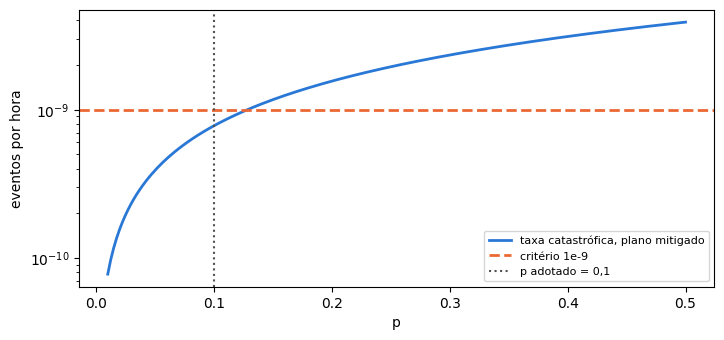

A conclusão 'atende o critério' vale só se p < 0,13 — e p não foi estimado.


In [17]:
# Exercício 10 — solução
taxa_disco_mit = FALHAS_MIT_IMPRESSO / HORAS
print(f"a) p máximo = {CRITERIO / (2 * taxa_disco_mit):.3f}")
p = np.linspace(0.01, 0.5, 200)
fig, ax = plt.subplots()
ax.plot(p, 2 * taxa_disco_mit * p, color="#2a78d6", lw=2, label="taxa catastrófica, plano mitigado")
ax.axhline(CRITERIO, color="#eb6834", ls="--", lw=2, label="critério 1e-9")
ax.axvline(0.1, color="#52514e", ls=":", label="p adotado = 0,1")
ax.set_yscale("log"); ax.set_xlabel("p"); ax.set_ylabel("eventos por hora"); ax.legend(fontsize=8)
plt.show()
print("A conclusão 'atende o critério' vale só se p < 0,13 — e p não foi estimado.")

### 8.2 Duas mudanças ao mesmo tempo

O plano mitigado muda o intervalo (6.000 → 3.000 h) **e** a eficácia (75% → 95%) de uma vez. Assim, não se sabe qual mudança reduziu as falhas.

In [18]:
# Exercício 11 — solução
res, semente = {}, 3000
for inspecao in (6_000, 3_000):
    for eficacia in (0.75, 0.95):
        semente += 1
        r = repetir(inspecao, eficacia, 200, semente)
        res[(inspecao, eficacia)] = r.mean()
        print(f"{inspecao:>6} h  {eficacia:.2f}  {r.mean():.2f} ± {r.std(ddof=1) / math.sqrt(r.size):.2f}")
b = res[(6000, 0.75)]
print(f"Só intervalo: {b:.2f} -> {res[(3000, 0.75)]:.2f}; só eficácia: {b:.2f} -> {res[(6000, 0.95)]:.2f}; "
      f"as duas: {res[(3000, 0.95)]:.2f}")
print(f"Produto das frações: {res[(3000, 0.75)] / b * res[(6000, 0.95)] / b * b:.2f} — os efeitos se multiplicam, aproximadamente.")

  6000 h  0.75  6.78 ± 0.16


  6000 h  0.95  2.32 ± 0.11


  3000 h  0.75  1.58 ± 0.09


  3000 h  0.95  0.49 ± 0.05
Só intervalo: 6.78 -> 1.58; só eficácia: 6.78 -> 2.32; as duas: 0.49
Produto das frações: 0.54 — os efeitos se multiplicam, aproximadamente.


## 9. Capacidade 6 — Verificar não é validar

Reproduzimos, replicamos e verificamos. Nada disso diz se o modelo representa um disco ou uma estrutura reais. Os parâmetros dos casos são ilustrativos e não foram calibrados para uma frota operacional específica. Um resultado pode ser perfeitamente reproduzível e estar errado sobre o mundo.

**Exercício 12 — pontos esperados.**

- Falhas de disco confirmadas, com a idade da peça e as horas da frota → β e η da Weibull.
- Achados de inspeção, peças rejeitadas e reinspeções → eficácia da inspeção.
- Consequência de cada falha de disco (contida ou não) → fração catastrófica $p$.
- Trincas medidas, com ciclos acumulados → $a_0$, $A$ e curva POD.

Cuidado de definição: falha = falha confirmada, e não remoção. Remoções com NFF e retiradas por limite de vida entram como observações censuradas.

## 10. As limitações do estudo, num quadro

Reúna o que você encontrou. Para cada limitação, indique a evidência e o efeito sobre a decisão.

**Exercício 13 — exemplos de respostas.**

| Hipótese ou limitação | Evidência a apresentar | Consequência para o uso |
|---|---|---|
| Hazard e taxa média de frota são grandezas diferentes | Definições e cálculo com e sem intervenções | A idade calculada não determina diretamente o intervalo de inspeção |
| Conversão da taxa do disco em taxa catastrófica depende de p | Sensibilidade à fração p | A comparação com o critério é condicional ao cenário |
| Precisão finita de Monte Carlo | Média, EP, n e erro relativo | Reportar incerteza e adequar o número de réplicas |
| Reciclagem e alinhamento de vetores diferem entre linguagens | Teste pequeno da exposição | Documentar a regra implementada antes de comparar taxas |
| Intervalo e eficácia variam em conjunto | Experimento fatorial | Separar efeitos e avaliar a interação |
| Parâmetros ilustrativos | Identificação das entradas e suas faixas | Calibrar e avaliar com dados independentes antes do uso operacional |
| Reparo binário, frota fechada e crescimento exponencial de trinca | Especificação e experimentos de cenário | Delimitar o domínio de aplicação e testar alternativas |


## 11. O que guardar

1. **Reproduzir** exige código, dados, semente e ambiente; o resultado deve ser idêntico.
2. **Replicar** exige uma descrição do método suficiente para reescrevê-lo; o resultado deve ser compatível dentro de uma tolerância declarada.
3. Nenhum dos dois substitui **verificar** o código, **testar a robustez** da decisão e **validar** o modelo com dados.

Registre código, dados, ambiente, sementes e critérios de comparação para que outra pessoa possa refazer os experimentos. Na tarefa simplificada, use `../enviar_alunos/tarefa_safety.ipynb` para comparar os planos estruturais com o código fornecido, testar crescimento da trinca +20% e interpretar os limites. A entrega é apenas o notebook executado.